In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\shali\OneDrive\Desktop\FinanceX\data\anomaly_datasets.csv")
df.head()

,customer_id,transaction_id,amount,category,user_average_amount,category_average_amount,transaction_frequency,balance,day_of_week,transaction_hour,is_weekend,amount_vs_user_avg,amount_vs_category_avg,recent_transaction_count
0,CUST_00001,TXN_0000001,2183.70,entertainment,3926.16,2662.88,1.00,33798.83,3,9,0,0.556192,0.8201,0
1,CUST_00001,TXN_0000002,7180.30,travel,2183.70,6589.85,2.00,26618.53,3,6,0,3.288135,1.0896,0
2,CUST_00001,TXN_0000003,7347.68,others,4682.00,3177.73,3.00,19270.85,0,8,0,1.569346,2.3122,2
3,CUST_00001,TXN_0000004,3432.40,shopping,5570.56,3353.52,4.00,15838.45,4,16,0,0.616168,1.0235,0
4,CUST_00001,TXN_0000005,5670.70,travel,5036.02,6589.85,3.49,10167.75,2,17,0,1.126028,0.8605,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   amount                    30000 non-null  float64
 1   category                  30000 non-null  object 
 2   user_average_amount       30000 non-null  float64
 3   category_average_amount   30000 non-null  float64
 4   transaction_frequency     30000 non-null  float64
 5   balance                   30000 non-null  float64
 6   day_of_week               30000 non-null  int64  
 7   transaction_hour          30000 non-null  int64  
 8   is_weekend                30000 non-null  int64  
 9   amount_vs_user_avg        30000 non-null  float64
 10  amount_vs_category_avg    30000 non-null  float64
 11  recent_transaction_count  30000 non-null  int64  
dtypes: float64(7), int64(4), object(1)
memory usage: 2.7+ MB


In [ ]:
df.drop(columns=['customer_id','transaction_id'], inplace=True)

In [11]:
x = df

In [16]:
cat_feature = df.select_dtypes(include=['object']).columns
num_feature = df.select_dtypes(include=['int64','float64']).columns

#### Isolation forest 

In [37]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            num_feature
        ),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            cat_feature
        )
    ]
)

In [40]:
model = IsolationForest(
    n_estimators=200,
    max_samples="auto",
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

In [41]:
anomaly_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

In [43]:
anomaly_pipeline.fit(x)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['amount','category','user_average_amount',...,'amount_vs_user_avg', 'amount_vs_category_avg','recent_transaction_count']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `f

In [45]:
predictions = anomaly_pipeline.predict(x)

print("Prediction shape:", predictions.shape)

print("\nUnique predictions:")
print(np.unique(predictions, return_counts=True))

Prediction shape: (30000,)

Unique predictions:
(array([-1,  1]), array([ 6800, 23200]))


In [47]:
anomaly_scores = anomaly_pipeline.decision_function(x)

print("Minimum score:", anomaly_scores.min())
print("Maximum score:", anomaly_scores.max())
print("Mean score:", anomaly_scores.mean())

Minimum score: -0.1979373216767505
Maximum score: 0.12377862471331352
Mean score: 0.0347910944525389


In [ ]:
results = df.copy()

results["anomaly_prediction"] = predictions
results["anomaly_score"] = anomaly_scores

,amount,category,user_average_amount,category_average_amount,transaction_frequency,balance,day_of_week,transaction_hour,is_weekend,amount_vs_user_avg,amount_vs_category_avg,recent_transaction_count,anomaly_prediction,anomaly_score
0,2183.70,entertainment,3926.16,2662.88,1.00,33798.83,3,9,0,0.556192,0.8201,0,1,0.001704
1,7180.30,travel,2183.70,6589.85,2.00,26618.53,3,6,0,3.288135,1.0896,0,-1,-0.041113
2,7347.68,others,4682.00,3177.73,3.00,19270.85,0,8,0,1.569346,2.3122,2,-1,-0.000166
3,3432.40,shopping,5570.56,3353.52,4.00,15838.45,4,16,0,0.616168,1.0235,0,1,0.030651
4,5670.70,travel,5036.02,6589.85,3.49,10167.75,2,17,0,1.126028,0.8605,0,1,0.007473


In [55]:
results.head()

,amount,category,user_average_amount,category_average_amount,transaction_frequency,balance,day_of_week,transaction_hour,is_weekend,amount_vs_user_avg,amount_vs_category_avg,recent_transaction_count,anomaly_prediction,anomaly_score
0,2183.70,entertainment,3926.16,2662.88,1.00,33798.83,3,9,0,0.556192,0.8201,0,1,0.001704
1,7180.30,travel,2183.70,6589.85,2.00,26618.53,3,6,0,3.288135,1.0896,0,-1,-0.041113
2,7347.68,others,4682.00,3177.73,3.00,19270.85,0,8,0,1.569346,2.3122,2,-1,-0.000166
3,3432.40,shopping,5570.56,3353.52,4.00,15838.45,4,16,0,0.616168,1.0235,0,1,0.030651
4,5670.70,travel,5036.02,6589.85,3.49,10167.75,2,17,0,1.126028,0.8605,0,1,0.007473


In [49]:
normal_count = (results["anomaly_prediction"] == 1).sum()
anomaly_count = (results["anomaly_prediction"] == -1).sum()

print("Normal transactions:", normal_count)
print("Anomalous transactions:", anomaly_count)

print(
    "Anomaly percentage:",
    round(anomaly_count / len(results) * 100, 2),
    "%"
)

Normal transactions: 23200
Anomalous transactions: 6800
Anomaly percentage: 22.67 %


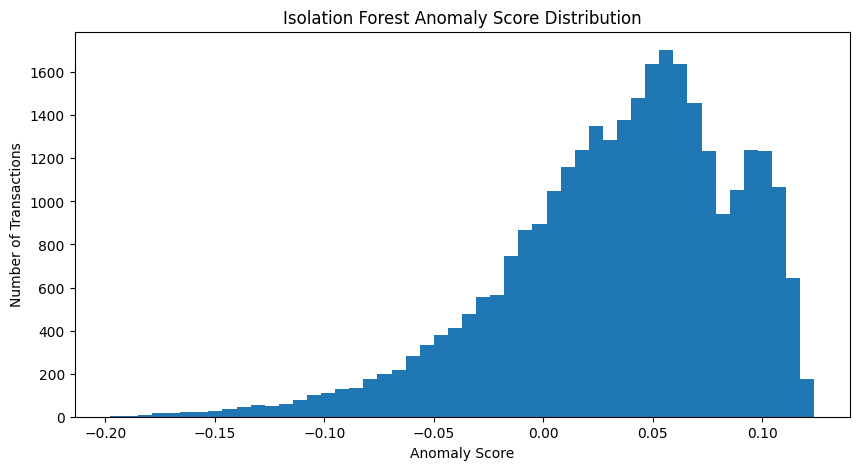

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(results["anomaly_score"],bins=50)
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Transactions")
plt.title("Isolation Forest Anomaly Score Distribution")

plt.show()

In [59]:
import joblib
joblib.dump(
    anomaly_pipeline,
    r"C:\Users\shali\OneDrive\Desktop\FinanceX\model\FinanceX_anomaly_model.pkl"
)

['C:\\Users\\shali\\OneDrive\\Desktop\\FinanceX\\model\\FinanceX_anomaly_model.pkl']